# NABIDH Synthetic EHR — Exploratory Data Analysis

**SYNTHETIC — NOT REAL PATIENT DATA**

General descriptive analysis of the raw synthetic extract (`output/*.csv`) produced by `generate_nabidh_synthetic_ehr.py`. This notebook explores cohort structure, record volume, coding patterns, lab distributions, and intentional missingness — without building derived predictor or outcome tables.

**Requirements:** `pip install pandas numpy matplotlib seaborn jupyter`

In [1]:
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

DATA_DIR = Path("output")
DATA_END = pd.Timestamp("2025-12-31")
SYNTHETIC_BANNER = "# SYNTHETIC — NOT REAL PATIENT DATA"


def load_table(name: str) -> pd.DataFrame:
    path = DATA_DIR / f"{name}.csv"
    df = pd.read_csv(path, skiprows=1, comment="#")
    print(f"{name:14s} {len(df):>10,} rows  |  {len(df.columns)} columns")
    return df


def pct(n, d):
    return 100 * n / d if d else 0

Matplotlib is building the font cache; this may take a moment.


## 1. Load raw tables

In [2]:
patients = load_table("patients")
encounters = load_table("encounters")
conditions = load_table("conditions")
medications = load_table("medications")
observations = load_table("observations")
labs = load_table("labs")

n_patients = patients["patient_id"].nunique()
print(f"\nUnique patients: {n_patients:,}")

patients          100,000 rows  |  6 columns


encounters        773,024 rows  |  5 columns


conditions        459,143 rows  |  6 columns
medications        54,146 rows  |  6 columns


observations      993,494 rows  |  7 columns


labs              509,735 rows  |  6 columns

Unique patients: 100,000


## 2. Cohort demographics

,metric,value
0,Patients,"100,000"
1,Age median (years),55
2,Age IQR,39–70
3,Male %,57.9%
4,Female %,42.1%
5,Education missing %,74.9%
6,Ethnicity 'Not recorded' %,6.0%


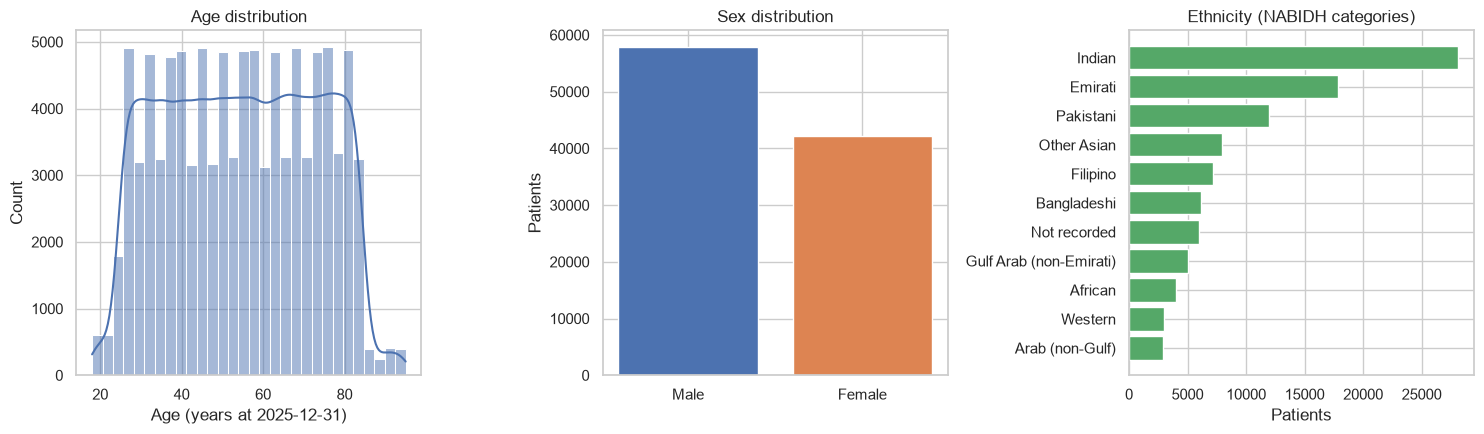

In [3]:
patients["date_of_birth"] = pd.to_datetime(patients["date_of_birth"])
patients["age_years"] = ((DATA_END - patients["date_of_birth"]).dt.days // 365).astype(int)
patients["education_missing"] = patients["education_level"].isna() | (patients["education_level"] == "")

demo_summary = pd.DataFrame({
    "metric": [
        "Patients",
        "Age median (years)",
        "Age IQR",
        "Male %",
        "Female %",
        "Education missing %",
        "Ethnicity 'Not recorded' %",
    ],
    "value": [
        f"{n_patients:,}",
        f"{patients['age_years'].median():.0f}",
        f"{patients['age_years'].quantile(0.25):.0f}–{patients['age_years'].quantile(0.75):.0f}",
        f"{pct((patients['sex']=='Male').sum(), n_patients):.1f}%",
        f"{pct((patients['sex']=='Female').sum(), n_patients):.1f}%",
        f"{pct(patients['education_missing'].sum(), n_patients):.1f}%",
        f"{pct((patients['ethnicity_nabidh']=='Not recorded').sum(), n_patients):.1f}%",
    ],
})
display(demo_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(patients["age_years"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age (years at 2025-12-31)")

sex_counts = patients["sex"].value_counts()
axes[1].bar(sex_counts.index, sex_counts.values, color=["#4C72B0", "#DD8452"])
axes[1].set_title("Sex distribution")
axes[1].set_ylabel("Patients")

eth_order = patients["ethnicity_nabidh"].value_counts().index
eth_counts = patients["ethnicity_nabidh"].value_counts().reindex(eth_order)
axes[2].barh(eth_counts.index[::-1], eth_counts.values[::-1], color="#55A868")
axes[2].set_title("Ethnicity (NABIDH categories)")
axes[2].set_xlabel("Patients")

plt.tight_layout()
plt.show()

## 3. Record volume and linkage

,table,rows,patients_with_data,pct_patients,median_rows_per_patient
0,encounters,773024,98749,98.7,7.0
1,conditions,459143,100000,100.0,4.0
2,medications,54146,43822,43.8,1.0
3,observations,993494,97370,97.4,10.0
4,labs,509735,74977,75.0,6.0


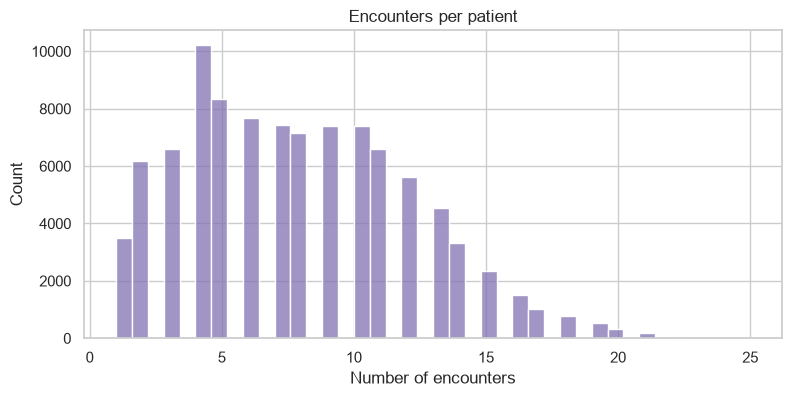

In [4]:
table_rows = pd.Series({
    "encounters": len(encounters),
    "conditions": len(conditions),
    "medications": len(medications),
    "observations": len(observations),
    "labs": len(labs),
})

patients_with = pd.Series({
    "≥1 encounter": encounters["patient_id"].nunique(),
    "≥1 condition": conditions["patient_id"].nunique(),
    "≥1 medication": medications["patient_id"].nunique(),
    "≥1 observation": observations["patient_id"].nunique(),
    "≥1 lab": labs["patient_id"].nunique(),
})

linkage = pd.DataFrame({
    "table": table_rows.index,
    "rows": table_rows.values,
    "patients_with_data": patients_with.values,
    "pct_patients": [pct(v, n_patients) for v in patients_with.values],
    "median_rows_per_patient": [
        encounters.groupby("patient_id").size().median(),
        conditions.groupby("patient_id").size().median(),
        medications.groupby("patient_id").size().median(),
        observations.groupby("patient_id").size().median(),
        labs.groupby("patient_id").size().median(),
    ],
})
display(linkage.round({"pct_patients": 1, "median_rows_per_patient": 1}))

enc_per_pt = encounters.groupby("patient_id").size()
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(enc_per_pt, bins=40, ax=ax, color="#8172B2")
ax.set_title("Encounters per patient")
ax.set_xlabel("Number of encounters")
plt.show()

## 4. Temporal coverage

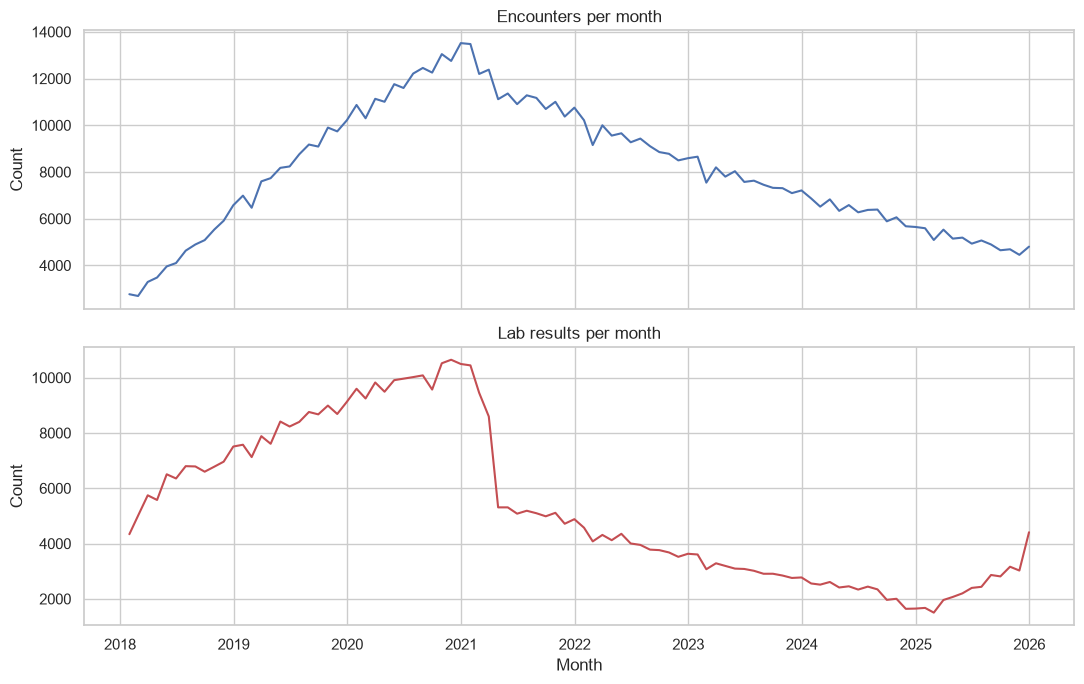

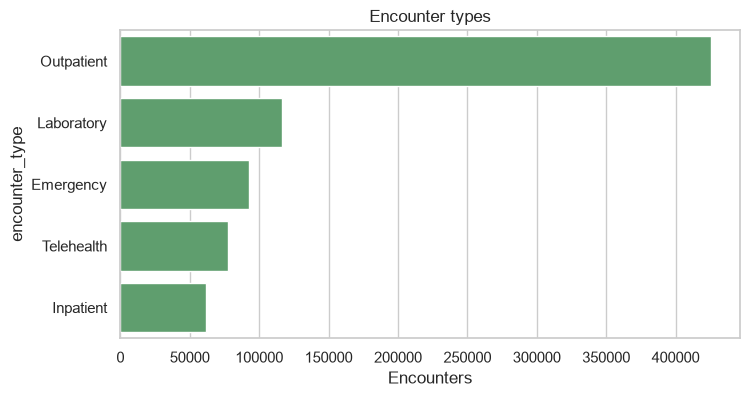

In [5]:
encounters["encounter_date"] = pd.to_datetime(encounters["encounter_date"])
conditions["recorded_date"] = pd.to_datetime(conditions["recorded_date"])
labs["date"] = pd.to_datetime(labs["date"])

enc_monthly = encounters.set_index("encounter_date").resample("ME").size()
lab_monthly = labs.set_index("date").resample("ME").size()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(enc_monthly.index, enc_monthly.values, color="#4C72B0")
axes[0].set_title("Encounters per month")
axes[0].set_ylabel("Count")

axes[1].plot(lab_monthly.index, lab_monthly.values, color="#C44E52")
axes[1].set_title("Lab results per month")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()

enc_type = encounters["encounter_type"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=enc_type.values, y=enc_type.index, ax=ax, color="#55A868")
ax.set_title("Encounter types")
ax.set_xlabel("Encounters")
plt.show()

## 5. Conditions — prevalence and coding systems

Records by code system:


,rows
code_system,
ICD-10,318923
SNOMED,140220


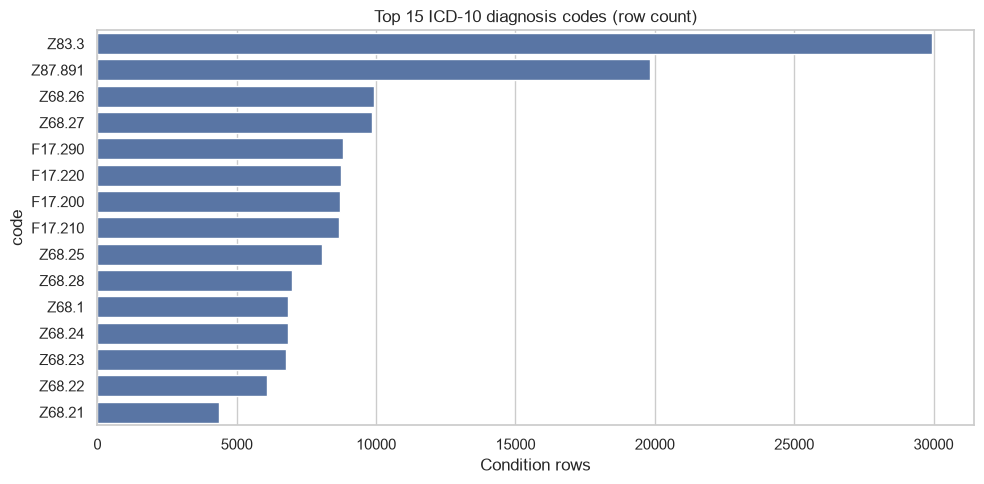

,theme,patients,pct_cohort
0,Obesity (E66.x),32922,32.922
5,Family hx diabetes (Z83.3),29955,29.955
2,Type 2 diabetes dx (E11.x),24000,24.000
1,Hypertension (I10–I1A),22691,22.691
4,Prediabetes (R73.x),20060,20.060
6,GDM (O24.x),8372,8.372
7,PCOS (E28.2),1309,1.309
3,Type 1 diabetes dx (E10.x),500,0.500


In [6]:
cond_by_system = conditions["code_system"].value_counts()
top_icd = (
    conditions.loc[conditions["code_system"] == "ICD-10", "code"]
    .value_counts()
    .head(15)
)

print("Records by code system:")
display(cond_by_system.to_frame("rows"))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_icd.values, y=top_icd.index, ax=ax, color="#4C72B0")
ax.set_title("Top 15 ICD-10 diagnosis codes (row count)")
ax.set_xlabel("Condition rows")
plt.tight_layout()
plt.show()

# Clinical themes (patient-level presence)
def patients_with_prefix(prefix: str) -> int:
    mask = conditions["code"].astype(str).str.startswith(prefix)
    return conditions.loc[mask, "patient_id"].nunique()

def patients_with_exact(code: str) -> int:
    return conditions.loc[conditions["code"] == code, "patient_id"].nunique()

def patients_with_htn() -> int:
    prefixes = ("I10", "I11", "I12", "I13", "I15", "I16", "I1A")
    mask = conditions["code"].astype(str).apply(lambda c: any(c.startswith(p) for p in prefixes))
    return conditions.loc[mask, "patient_id"].nunique()

clinical_flags = pd.DataFrame({
    "theme": [
        "Obesity (E66.x)",
        "Hypertension (I10–I1A)",
        "Type 2 diabetes dx (E11.x)",
        "Type 1 diabetes dx (E10.x)",
        "Prediabetes (R73.x)",
        "Family hx diabetes (Z83.3)",
        "GDM (O24.x)",
        "PCOS (E28.2)",
    ],
    "patients": [
        patients_with_prefix("E66"),
        patients_with_htn(),
        patients_with_prefix("E11"),
        patients_with_prefix("E10"),
        patients_with_prefix("R73"),
        patients_with_exact("Z83.3"),
        patients_with_prefix("O24"),
        patients_with_exact("E28.2"),
    ],
})
clinical_flags["pct_cohort"] = clinical_flags["patients"].apply(lambda x: pct(x, n_patients))
display(clinical_flags.sort_values("patients", ascending=False))

## 6. Medications — ATC class utilization

,rows,patients,median_rx_prior_year
atc_class,,,
A10,19203,18919,7.0
C10,13949,13949,7.0
C09,6511,6511,5.0
C07,4521,4521,5.0
H02,2338,2338,2.0
C03,2181,2181,5.0
C08,2163,2163,5.0
C02,2137,2137,5.0
N05,1143,1143,7.0


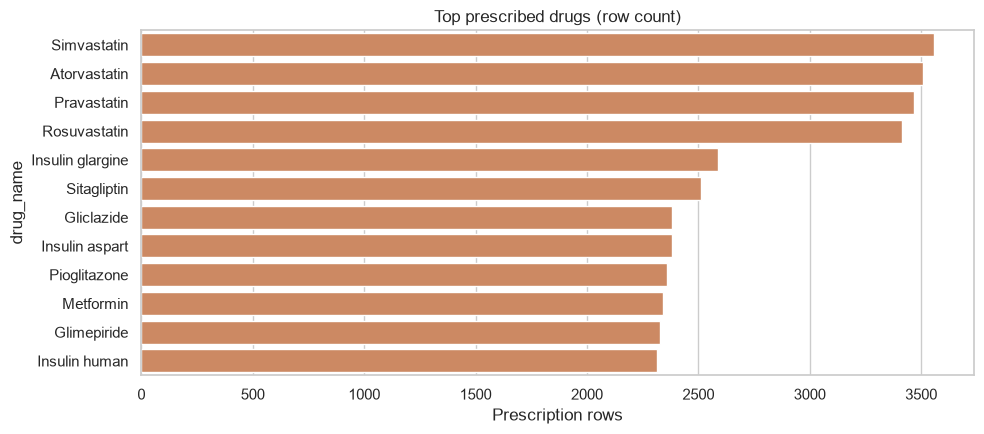

In [7]:
medications["atc_class"] = medications["atc_code"].str[:3]
med_class = medications.groupby("atc_class").agg(
    rows=("atc_code", "size"),
    patients=("patient_id", "nunique"),
    median_rx_prior_year=("n_prescriptions_prior_year", "median"),
).sort_values("patients", ascending=False)

display(med_class.head(10))

top_drugs = medications["drug_name"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=top_drugs.values, y=top_drugs.index, ax=ax, color="#DD8452")
ax.set_title("Top prescribed drugs (row count)")
ax.set_xlabel("Prescription rows")
plt.tight_layout()
plt.show()

## 7. Laboratory results

,loinc,test_name,unit,n,patients,median,p25,p75
0,1521-4,Glucose [Mass/volume] in Serum or Plasma --2 h...,mg/dL,65098,18604,117.0,93.0,148.0
1,1558-6,Fasting glucose [Mass/volume] in Serum or Plasma,mg/dL,198684,56987,92.0,81.0,116.0
2,4548-4,Hemoglobin A1c/Hemoglobin.total in Blood,%,245953,67919,5.4,5.1,6.1


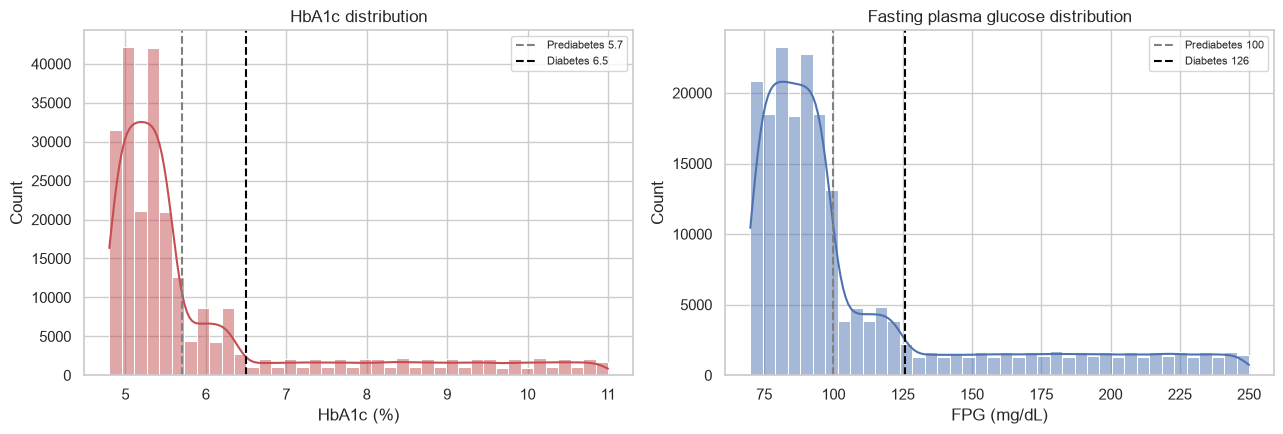

HbA1c value bands (all lab rows, not patient-level):


,lab_rows
value,
Normal (<5.7),168243
Diabetes range (≥6.5),47437
Prediabetes (5.7–6.4),30273


In [8]:
lab_summary = labs.groupby(["loinc", "test_name", "unit"]).agg(
    n=("value", "size"),
    patients=("patient_id", "nunique"),
    median=("value", "median"),
    p25=("value", lambda s: s.quantile(0.25)),
    p75=("value", lambda s: s.quantile(0.75)),
).reset_index()
display(lab_summary)

hba1c = labs.loc[labs["loinc"] == "4548-4", "value"].astype(float)
fpg = labs.loc[labs["loinc"] == "1558-6", "value"].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(hba1c, bins=40, kde=True, ax=axes[0], color="#C44E52")
axes[0].axvline(5.7, ls="--", color="gray", label="Prediabetes 5.7")
axes[0].axvline(6.5, ls="--", color="black", label="Diabetes 6.5")
axes[0].set_title("HbA1c distribution")
axes[0].set_xlabel("HbA1c (%)")
axes[0].legend(fontsize=8)

sns.histplot(fpg, bins=40, kde=True, ax=axes[1], color="#4C72B0")
axes[1].axvline(100, ls="--", color="gray", label="Prediabetes 100")
axes[1].axvline(126, ls="--", color="black", label="Diabetes 126")
axes[1].set_title("Fasting plasma glucose distribution")
axes[1].set_xlabel("FPG (mg/dL)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

hba1c_bands = pd.cut(
    hba1c,
    bins=[0, 5.6, 6.4, 20],
    labels=["Normal (<5.7)", "Prediabetes (5.7–6.4)", "Diabetes range (≥6.5)"],
    right=True,
)
print("HbA1c value bands (all lab rows, not patient-level):")
display(hba1c_bands.value_counts().to_frame("lab_rows"))

## 8. Observations — anthropometrics, vitals, lifestyle

,rows,patients,pct_patients
concept,,,
BMI,209819,70038,70.038
height_cm,209819,70038,70.038
weight_kg,209819,70038,70.038
smoking_status,65048,65048,65.048
diastolic_bp,119745,59917,59.917
systolic_bp,119745,59917,59.917
hip_cm,15051,15051,15.051
waist_cm,15051,15051,15.051
alcohol_use,12003,12003,12.003


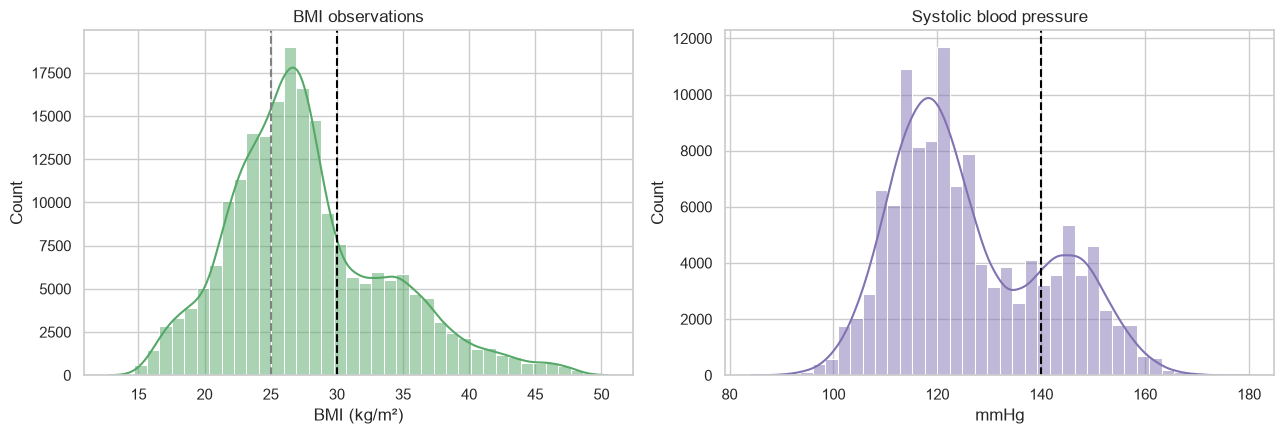

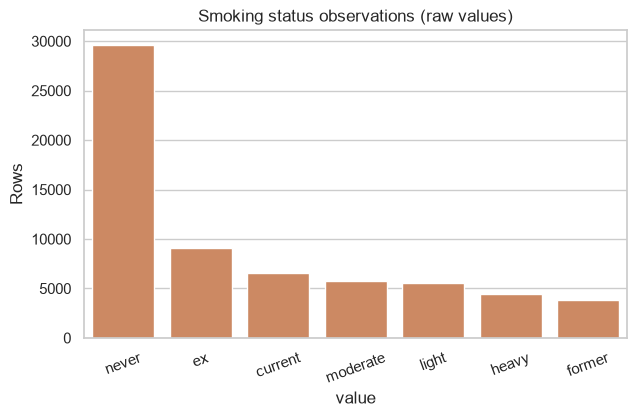

In [9]:
obs_coverage = observations.groupby("concept").agg(
    rows=("patient_id", "size"),
    patients=("patient_id", "nunique"),
).assign(pct_patients=lambda d: d["patients"] / n_patients * 100)
obs_coverage = obs_coverage.sort_values("patients", ascending=False)
display(obs_coverage)

bmi = observations.loc[observations["concept"] == "BMI", "value"].astype(float)
sbp = observations.loc[observations["concept"] == "systolic_bp", "value"].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(bmi, bins=40, kde=True, ax=axes[0], color="#55A868")
axes[0].axvline(25, ls="--", color="gray")
axes[0].axvline(30, ls="--", color="black")
axes[0].set_title("BMI observations")
axes[0].set_xlabel("BMI (kg/m²)")

sns.histplot(sbp, bins=40, kde=True, ax=axes[1], color="#8172B2")
axes[1].axvline(140, ls="--", color="black")
axes[1].set_title("Systolic blood pressure")
axes[1].set_xlabel("mmHg")

plt.tight_layout()
plt.show()

smoking = observations.loc[observations["concept"] == "smoking_status", "value"].value_counts()
if len(smoking):
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(x=smoking.index, y=smoking.values, ax=ax, color="#DD8452")
    ax.set_title("Smoking status observations (raw values)")
    ax.set_ylabel("Rows")
    plt.xticks(rotation=20)
    plt.show()

## 9. Intentional missingness snapshot

,field,pct_missing
4,pack_years,94.5
5,self_rated_health,88.1
6,alcohol_use,88.0
2,waist_cm,84.9
3,hip_cm,84.9
0,education_level,74.9
1,family_history (Z83.3),70.0
7,smoking_status,35.0
8,any_lab,25.0


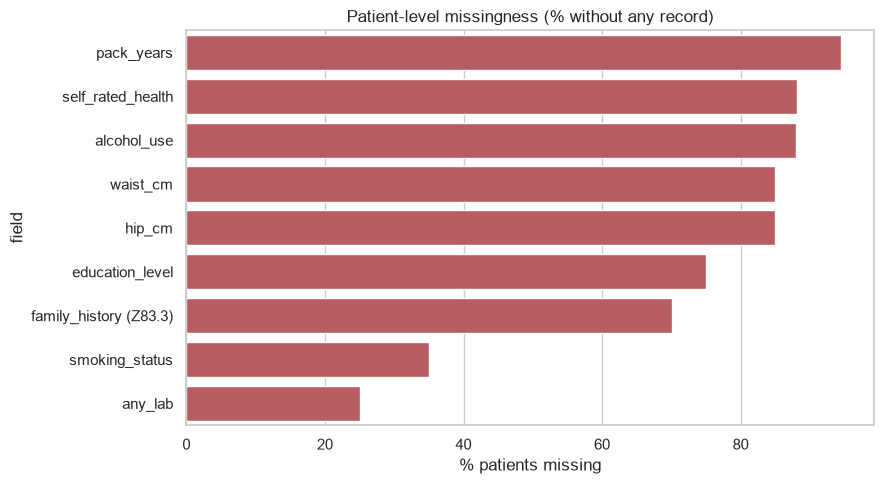

In [10]:
obs_concepts = {"waist_cm", "hip_cm", "pack_years", "self_rated_health", "alcohol_use", "BMI", "smoking_status"}
obs_patients = observations.groupby("concept")["patient_id"].nunique()

missingness = pd.DataFrame({
    "field": [
        "education_level",
        "family_history (Z83.3)",
        "waist_cm",
        "hip_cm",
        "pack_years",
        "self_rated_health",
        "alcohol_use",
        "smoking_status",
        "any_lab",
    ],
    "pct_missing": [
        pct(patients["education_missing"].sum(), n_patients),
        pct(n_patients - patients_with_exact("Z83.3"), n_patients),
        pct(n_patients - obs_patients.get("waist_cm", 0), n_patients),
        pct(n_patients - obs_patients.get("hip_cm", 0), n_patients),
        pct(n_patients - obs_patients.get("pack_years", 0), n_patients),
        pct(n_patients - obs_patients.get("self_rated_health", 0), n_patients),
        pct(n_patients - obs_patients.get("alcohol_use", 0), n_patients),
        pct(n_patients - obs_patients.get("smoking_status", 0), n_patients),
        pct(n_patients - labs["patient_id"].nunique(), n_patients),
    ],
})
missingness = missingness.sort_values("pct_missing", ascending=False)
display(missingness.round({"pct_missing": 1}))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=missingness, y="field", x="pct_missing", ax=ax, color="#C44E52")
ax.set_title("Patient-level missingness (% without any record)")
ax.set_xlabel("% patients missing")
plt.tight_layout()
plt.show()

## 10. Diabetes-defining records — descriptive timing check

Descriptive only: identifies raw diabetes-defining labs/diagnoses/meds and measures the gap from each patient's earliest dated record. No outcome labels are created.

Patients with any diabetes-defining record: 24,500 (24.5% of cohort)


,patients
<=30 days,16500
31–364 days,0
>=365 days,8000


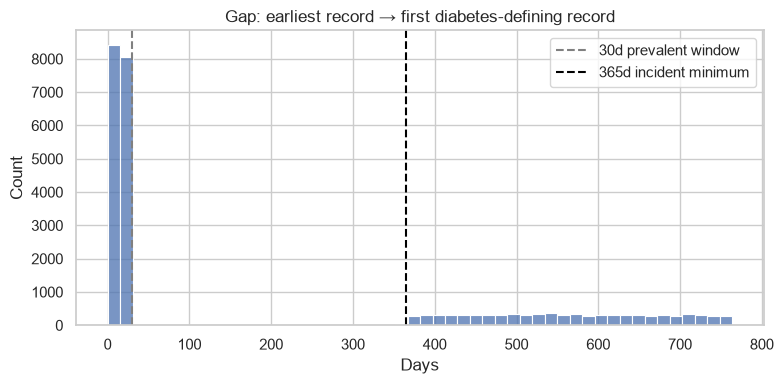

Source of first diabetes-defining record:


,patients
source,
lab,61063
dx,24500
med,19203


In [11]:
def is_dm_lab(row):
    v = float(row["value"])
    if row["loinc"] == "4548-4":
        return v >= 6.5
    if row["loinc"] == "1558-6":
        return v >= 126
    if row["loinc"] == "1521-4":
        return v >= 200
    return False

dm_labs = labs.loc[labs.apply(is_dm_lab, axis=1), ["patient_id", "date"]]
dm_cond = conditions.loc[
    conditions["code"].astype(str).str.startswith(("E10", "E11")),
    ["patient_id", "recorded_date"],
].rename(columns={"recorded_date": "date"})
dm_meds = medications.loc[
    medications["atc_code"].str.startswith("A10"),
    ["patient_id", "prescription_date"],
].rename(columns={"prescription_date": "date"})

dm_events = pd.concat([
    dm_labs.assign(source="lab"),
    dm_cond.assign(source="dx"),
    dm_meds.assign(source="med"),
], ignore_index=True)
dm_events["date"] = pd.to_datetime(dm_events["date"])

first_dm = dm_events.groupby("patient_id")["date"].min().rename("first_dm_date")

earliest = pd.concat([
    encounters.assign(d=encounters["encounter_date"])[["patient_id", "d"]],
    conditions.assign(d=conditions["recorded_date"])[["patient_id", "d"]],
    medications.assign(d=pd.to_datetime(medications["prescription_date"]))[["patient_id", "d"]],
    observations.assign(d=pd.to_datetime(observations["date"]))[["patient_id", "d"]],
    labs.assign(d=labs["date"])[["patient_id", "d"]],
]).groupby("patient_id")["d"].min().rename("earliest_date")

timing = first_dm.to_frame().join(earliest, how="inner")
timing["gap_days"] = (timing["first_dm_date"] - timing["earliest_date"]).dt.days

buckets = pd.Series({
    "<=30 days": (timing["gap_days"] <= 30).sum(),
    "31–364 days": ((timing["gap_days"] > 30) & (timing["gap_days"] < 365)).sum(),
    ">=365 days": (timing["gap_days"] >= 365).sum(),
})
print(f"Patients with any diabetes-defining record: {len(timing):,} ({pct(len(timing), n_patients):.1f}% of cohort)")
display(buckets.to_frame("patients"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(timing["gap_days"], bins=50, ax=ax, color="#4C72B0")
ax.axvline(30, ls="--", color="gray", label="30d prevalent window")
ax.axvline(365, ls="--", color="black", label="365d incident minimum")
ax.set_title("Gap: earliest record → first diabetes-defining record")
ax.set_xlabel("Days")
ax.legend()
plt.tight_layout()
plt.show()

dm_source = dm_events.loc[dm_events.groupby("patient_id")["date"].transform("min") == dm_events["date"], "source"].value_counts()
print("Source of first diabetes-defining record:")
display(dm_source.to_frame("patients"))

## 11. Demographics vs clinical themes

Median age by T2D diagnosis presence:


,median_age
T2D_dx,
False,54.0
True,57.0


,n,rate,rate_pct
ethnicity_nabidh,,,
Bangladeshi,1528,0.247169,24.7
Pakistani,2954,0.246887,24.7
Not recorded,1468,0.246309,24.6
Gulf Arab (non-Emirati),1222,0.243620,24.4
African,978,0.242199,24.2
Arab (non-Gulf),696,0.240830,24.1
Emirati,4262,0.239129,23.9
Filipino,1703,0.238415,23.8
Other Asian,1881,0.236872,23.7


/var/folders/bc/kx2zxl915sd4d8gswr4p_5v00000gn/T/ipykernel_90542/1551689635.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=flags, x="T2D_dx", y="age_years", ax=ax, palette="Set2")


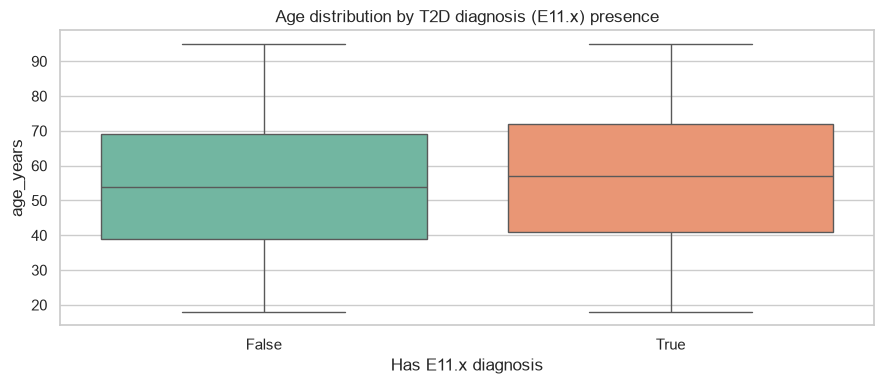

In [12]:
theme_codes = {
    "T2D_dx": "E11",
    "HTN_dx": "I10",
    "Obesity_dx": "E66",
    "Prediabetes_dx": "R73",
}

flags = patients[["patient_id", "sex", "age_years", "ethnicity_nabidh"]].copy()
for label, prefix in theme_codes.items():
    pids = conditions.loc[conditions["code"].astype(str).str.startswith(prefix), "patient_id"].unique()
    flags[label] = flags["patient_id"].isin(pids)

age_by_t2d = flags.groupby("T2D_dx")["age_years"].median()
print("Median age by T2D diagnosis presence:")
display(age_by_t2d.to_frame("median_age"))

eth_t2d = (
    flags.groupby("ethnicity_nabidh")["T2D_dx"]
    .agg(n="sum", rate="mean")
    .assign(rate_pct=lambda d: d["rate"] * 100)
    .sort_values("rate_pct", ascending=False)
    .head(10)
)
display(eth_t2d.round({"rate_pct": 1}))

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=flags, x="T2D_dx", y="age_years", ax=ax, palette="Set2")
ax.set_title("Age distribution by T2D diagnosis (E11.x) presence")
ax.set_xlabel("Has E11.x diagnosis")
plt.tight_layout()
plt.show()

## 12. Summary findings

Run the cell below after executing all sections to print a concise narrative report.

In [13]:
print("=" * 72)
print("SYNTHETIC NABIDH EHR — EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 72)
print(f"Cohort size: {n_patients:,} synthetic patients (2018–2025 window)")
print(f"Median age: {patients['age_years'].median():.0f} years | Male: {pct((patients['sex']=='Male').sum(), n_patients):.1f}%")
print(f"Total clinical rows: {len(encounters)+len(conditions)+len(medications)+len(observations)+len(labs):,}")
print(f"Median encounters/patient: {enc_per_pt.median():.0f}")
print()
print("Coding & comorbidity (patient-level):")
for _, row in clinical_flags.sort_values("patients", ascending=False).head(6).iterrows():
    print(f"  • {row['theme']}: {row['patients']:,} ({row['pct_cohort']:.1f}%)")
print()
print("Missingness highlights:")
for _, row in missingness.head(5).iterrows():
    print(f"  • {row['field']}: {row['pct_missing']:.1f}% patients without records")
print()
print("Diabetes-defining timing (descriptive):")
for idx, val in buckets.items():
    print(f"  • {idx}: {val:,} patients")
print()
print("Lab distributions:")
print(f"  • HbA1c median: {hba1c.median():.1f}% | FPG median: {fpg.median():.0f} mg/dL")
print(f"  • BMI observation median: {bmi.median():.1f} kg/m²")
print("=" * 72)

SYNTHETIC NABIDH EHR — EXPLORATORY DATA ANALYSIS SUMMARY
Cohort size: 100,000 synthetic patients (2018–2025 window)
Median age: 55 years | Male: 57.9%
Total clinical rows: 2,789,542
Median encounters/patient: 7

Coding & comorbidity (patient-level):
  • Obesity (E66.x): 32,922 (32.9%)
  • Family hx diabetes (Z83.3): 29,955 (30.0%)
  • Type 2 diabetes dx (E11.x): 24,000 (24.0%)
  • Hypertension (I10–I1A): 22,691 (22.7%)
  • Prediabetes (R73.x): 20,060 (20.1%)
  • GDM (O24.x): 8,372 (8.4%)

Missingness highlights:
  • pack_years: 94.5% patients without records
  • self_rated_health: 88.1% patients without records
  • alcohol_use: 88.0% patients without records
  • waist_cm: 84.9% patients without records
  • hip_cm: 84.9% patients without records

Diabetes-defining timing (descriptive):
  • <=30 days: 16,500 patients
  • 31–364 days: 0 patients
  • >=365 days: 8,000 patients

Lab distributions:
  • HbA1c median: 5.4% | FPG median: 92 mg/dL
  • BMI observation median: 26.8 kg/m²
